In [1]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\HP\Downloads\Dataset_digital_life_impact_on_habits\social_media_sleep_stress_productivity_11000.csv"
)

print(df.shape)
df.head()

(11000, 10)


,user_id,age,daily_screen_time_hours,social_media_hours,sleep_hours,exercise_minutes,study_work_hours,productivity_score,stress_level,platform
0,1,44,2.39,1.93,8.46,61,3.73,33.86,Low,YouTube
1,2,30,7.22,5.24,7.34,28,6.80,85.32,Low,YouTube
2,3,23,2.56,4.64,4.69,8,4.47,60.07,High,YouTube
3,4,36,8.75,4.89,5.05,53,9.53,36.46,Medium,LinkedIn
4,5,34,10.96,2.77,7.12,83,7.01,32.93,Medium,Instagram


In [2]:
data = df[["sleep_hours", "productivity_score"]].dropna()

X = data[["sleep_hours"]]
y = data["productivity_score"]

print(X.shape)
print(y.shape)

(11000, 1)
(11000,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8800, 1)
X_test: (2200, 1)
y_train: (8800,)
y_test: (2200,)


In [5]:
x = list(X_train["sleep_hours"])
y_values = list(y_train)

n = len(x)

print("Training observations:", n)
print("First 5 sleep values:", x[:5])
print("First 5 productivity values:", y_values[:5])

Training observations: 8800
First 5 sleep values: [6.52, 7.66, 7.08, 7.75, 8.66]
First 5 productivity values: [4.75, 81.1, 67.5, 68.79, 15.9]


In [6]:
mean_x = sum(x) / n
mean_y = sum(y_values) / n

print("Mean sleep:", mean_x)
print("Mean productivity:", mean_y)

Mean sleep: 5.9903125
Mean productivity: 50.52331477272727


Calculated Xbar and ybar(mean of sleep and productivity)

In [7]:
numerator = 0
denominator = 0

for i in range(n):

    numerator += (
        (x[i] - mean_x) *
        (y_values[i] - mean_y)
    )

    denominator += (x[i] - mean_x) ** 2

if denominator == 0:
    raise ValueError("Cannot estimate slope: X has zero variance")

b1 = numerator / denominator

print("Slope:", b1)

Slope: 0.29086999758535914


In [8]:
b0 = mean_y - b1 * mean_x

print("Intercept:", b0)

Intercept: 48.780912590316724


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Scikit-learn slope:", model.coef_[0])
print("Scikit-learn intercept:", model.intercept_)

Scikit-learn slope: 0.29086999758535886
Scikit-learn intercept: 48.780912590316724


Without scikit learn

In [10]:
manual_predictions = []

for sleep in X_test["sleep_hours"]:

    prediction = b0 + b1 * sleep

    manual_predictions.append(prediction)

print("First 5 manual predictions:")
print(manual_predictions[:5])

First 5 manual predictions:
[50.04037967986133, 49.82804458162402, 50.27889307788132, 51.09332907112033, 50.91008097264155]


With scikit learn

In [12]:
sklearn_predictions = model.predict(X_test)

print("First 5 Scikit-learn predictions:")
print(sklearn_predictions[:5])

First 5 Scikit-learn predictions:
[50.04037968 49.82804458 50.27889308 51.09332907 50.91008097]


It uses the slope and intercept previously learned by:model.fit(X_train, y_train)

In [13]:
import pandas as pd

comparison = pd.DataFrame({
    "Sleep Hours": X_test["sleep_hours"],
    "Actual Productivity": y_test,
    "Predicted Productivity": sklearn_predictions
})

comparison["Residual"] = (
    comparison["Actual Productivity"]
    - comparison["Predicted Productivity"]
)

display(comparison.head(10))

,Sleep Hours,Actual Productivity,Predicted Productivity,Residual
107,4.33,84.45,50.040380,34.409620
5484,3.60,13.60,49.828045,-36.228045
6998,5.15,10.22,50.278893,-40.058893
3984,7.95,23.55,51.093329,-27.543329
3111,7.32,98.37,50.910081,47.459919
4040,4.16,96.09,49.990932,46.099068
3013,7.71,76.42,51.023520,25.396480
6607,6.22,3.80,50.590124,-46.790124
4219,7.37,86.98,50.924624,36.055376
8750,6.28,99.62,50.607576,49.012424


In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict productivity for the test observations
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R-squared: {r2:.6f}")

MAE: 24.9715
MSE: 835.9089
RMSE: 28.9121
R-squared: -0.000247


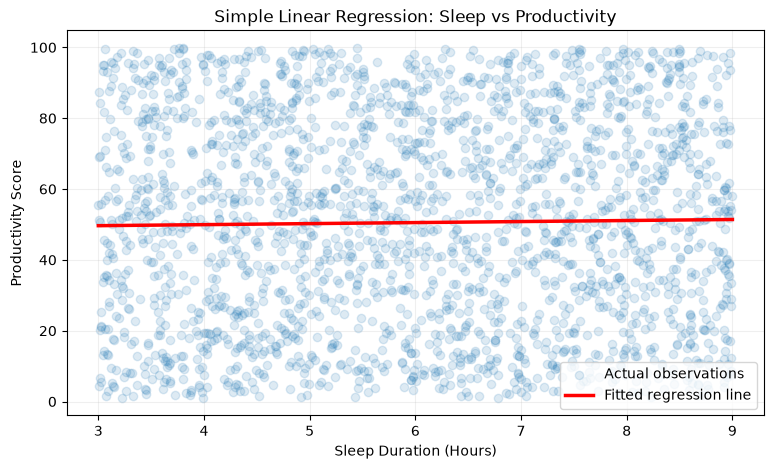

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

# Actual test observations
plt.scatter(
    X_test["sleep_hours"],
    y_test,
    alpha=0.15,
    label="Actual observations"
)

# Sort X values for a clean regression line
x_line = X_test.sort_values("sleep_hours")

# Generate predictions using the trained model
y_line = model.predict(x_line)

# Draw fitted regression line
plt.plot(
    x_line["sleep_hours"],
    y_line,
    color="red",
    linewidth=2.5,
    label="Fitted regression line"
)

plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Productivity Score")
plt.title("Simple Linear Regression: Sleep vs Productivity")
plt.legend()
plt.grid(alpha=0.2)
plt.show()